# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [15]:
VARIANT = 22   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 22 уже на месте: /content/data/variant_22
данные варианта: /content/data/variant_22
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [16]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.1.3 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [17]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
variant_info = json.loads(
    (DATA_DIR / "variant.json").read_text(encoding="utf-8")
)
print(json.dumps(variant_info, ensure_ascii=False, indent=2))

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
labels = pd.read_csv(DATA_DIR / "labels.csv")

print("\nПервые пять строк:")
display(labels.head())

print("Всего строк:", len(labels))

print("\nКоличество изображений каждой породы:")
breed_counts = (
    labels.groupby(["breed", "species"])
    .size()
    .reset_index(name="n_images")
)
display(breed_counts)


{
  "variant": 22,
  "dataset_version": "v1",
  "source": "release",
  "breeds": [
    "Birman",
    "Siamese",
    "newfoundland",
    "yorkshire_terrier"
  ],
  "species": {
    "Birman": "cat",
    "Siamese": "cat",
    "newfoundland": "dog",
    "yorkshire_terrier": "dog"
  },
  "class_ids": {
    "Birman": 0,
    "Siamese": 1,
    "newfoundland": 2,
    "yorkshire_terrier": 3
  },
  "names_ru": {
    "Birman": "бирманская кошка (священная бирма)",
    "Siamese": "сиамская кошка",
    "newfoundland": "ньюфаундленд",
    "yorkshire_terrier": "йоркширский терьер"
  },
  "n_images": 800,
  "n_boxes": 400,
  "n_trimaps": 800,
  "per_breed": {
    "Birman": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "Siamese": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "newfoundland": {
      "images": 200,
      "boxes": 100,
      "trimaps": 200
    },
    "yorkshire_terrier": {
      "images": 200,
      "boxes": 100,
      "trimaps": 20

,filename,breed,species,class_id
0,Birman_1.jpg,Birman,cat,0
1,Birman_2.jpg,Birman,cat,0
2,Birman_3.jpg,Birman,cat,0
3,Birman_4.jpg,Birman,cat,0
4,Birman_5.jpg,Birman,cat,0


Всего строк: 800

Количество изображений каждой породы:


,breed,species,n_images
0,Birman,cat,200
1,Siamese,cat,200
2,newfoundland,dog,200
3,yorkshire_terrier,dog,200


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [18]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

bgr = cv2.imread(str(example_path))
assert bgr is not None, f"Не удалось прочитать {example_path}"

# Координаты центрального пикселя: строка и столбец
cy = bgr.shape[0] // 2
cx = bgr.shape[1] // 2

print("Тип объекта:", type(bgr))
print("Форма массива:", bgr.shape)
print("Тип данных:", bgr.dtype)
print("Минимальное значение:", bgr.min())
print("Максимальное значение:", bgr.max())
print("Центральный пиксель BGR:", bgr[cy, cx])


Siamese_208.jpg
Тип объекта: <class 'numpy.ndarray'>
Форма массива: (333, 500, 3)
Тип данных: uint8
Минимальное значение: 0
Максимальное значение: 255
Центральный пиксель BGR: [ 89 141 207]


Центральный пиксель BGR: [ 89 141 207]
Центральный пиксель RGB: [207 141  89]


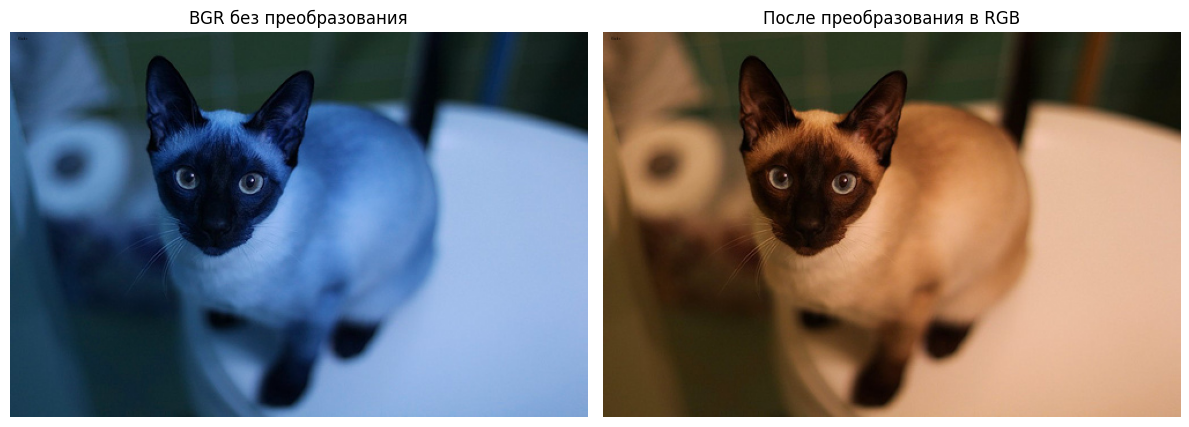

In [19]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

print("Центральный пиксель BGR:", bgr[cy, cx])
print("Центральный пиксель RGB:", rgb[cy, cx])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.title("BGR без преобразования")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.title("После преобразования в RGB")
plt.axis("off")

plt.tight_layout()
plt.show()


Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [20]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

print("Исходное RGB:", rgb.shape)
print("Оттенки серого:", gray.shape)
print("После ресайза:", resized.shape)
print("После отражения:", flipped.shape)

Исходное RGB: (333, 500, 3)
Оттенки серого: (333, 500)
После ресайза: (224, 224, 3)
После отражения: (333, 500, 3)


In [21]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


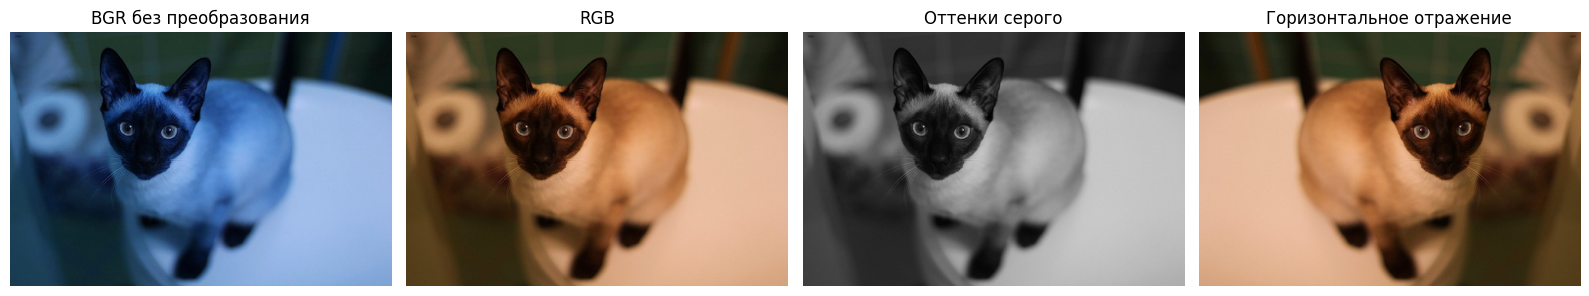

Сохранено: results/transforms.png


In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(bgr)
axes[0].set_title("BGR без преобразования")

axes[1].imshow(rgb)
axes[1].set_title("RGB")

axes[2].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Оттенки серого")

axes[3].imshow(flipped)
axes[3].set_title("Горизонтальное отражение")

for ax in axes:
    ax.axis("off")

fig.tight_layout()
fig.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

print("Сохранено:", RESULTS / "transforms.png")

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [23]:
label_by_file = labels.set_index("filename")

rows = []

for p in sorted(IMG_DIR.iterdir()):
    if not p.is_file() or p.name.startswith("."):
        continue

    # Считываем исходный формат, режим и размеры через Pillow
    with Image.open(p) as im:
        rec = {
            "filename": p.name,
            "ext": p.suffix.lower(),
            "pil_format": im.format,
            "mode": im.mode,
            "width": im.width,
            "height": im.height,
        }

    # Проверяем наличие файла с рамками головы
    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    # Добавляем породу и вид из таблицы меток
    label = label_by_file.loc[p.name]
    rec["breed"] = label["breed"]
    rec["species"] = label["species"]

    rows.append(rec)

info = pd.DataFrame(rows)

display(info.head())
print("Всего проверено изображений:", len(info))

print("\nКоличество файлов по цветовому режиму:")
display(info["mode"].value_counts().rename("n_images"))

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Birman_1.jpg,.jpg,JPEG,RGB,375,500,False,Birman,cat
1,Birman_10.jpg,.jpg,JPEG,RGB,500,330,True,Birman,cat
2,Birman_100.jpg,.jpg,JPEG,RGB,500,334,True,Birman,cat
3,Birman_101.jpg,.jpg,JPEG,RGB,500,375,True,Birman,cat
4,Birman_102.jpg,.jpg,JPEG,RGB,332,500,True,Birman,cat


Всего проверено изображений: 800

Количество файлов по цветовому режиму:


,n_images
mode,
RGB,800


In [24]:
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": int((info["species"] == "cat").sum()),
    "n_dogs": int((info["species"] == "dog").sum()),

    "width_min": int(info["width"].min()),
    "width_median": float(info["width"].median()),
    "width_max": int(info["width"].max()),

    "height_min": int(info["height"].min()),
    "height_median": float(info["height"].median()),
    "height_max": int(info["height"].max()),

    "n_non_rgb": int((info["mode"] != "RGB").sum()),

    "n_jpg_not_jpeg": int(
        (
            (info["ext"] == ".jpg")
            & (info["pil_format"] != "JPEG")
        ).sum()
    ),

    "n_with_xml": int(info["has_xml"].sum()),
    "xml_coverage_pct": round(
        100 * info["has_xml"].mean(), 2
    ),
}

# Количество изображений каждой породы — пригодится для выводов
for breed, count in info["breed"].value_counts().sort_index().items():
    summary[f"n_breed_{breed}"] = int(count)

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"],
    dtype=object,
)

summary_df.to_csv(RESULTS / "summary.csv", index=False)

display(summary_df)
print("Сохранено:", RESULTS / "summary.csv")

,metric,value
0,variant,22
1,n_files,800
2,n_breeds,4
3,n_cats,400
4,n_dogs,400
5,width_min,133
6,width_median,500.0
7,width_max,679
8,height_min,150
9,height_median,375.0


Сохранено: results/summary.csv


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [25]:
non_rgb = info[info["mode"] != "RGB"]

format_mismatch = info[
    (info["ext"] == ".jpg")
    & (info["pil_format"] != "JPEG")
]

print("Файлов не в RGB:", len(non_rgb))
display(non_rgb[["filename", "mode", "pil_format"]])

print("Файлов .jpg с другим форматом:", len(format_mismatch))
display(format_mismatch[["filename", "ext", "pil_format"]])

Файлов не в RGB: 0


,filename,mode,pil_format


Файлов .jpg с другим форматом: 0


,filename,ext,pil_format


In [26]:
problem_rows = info[
    (info["mode"] != "RGB")
    | (
        (info["ext"] == ".jpg")
        & (info["pil_format"] != "JPEG")
    )
]

if problem_rows.empty:
    comparison_name = example_name
    print(
        "Проблемных файлов нет. "
        "Сравниваем способы чтения на обычном RGB JPEG."
    )
else:
    comparison_name = problem_rows.iloc[0]["filename"]

comparison_path = IMG_DIR / comparison_name

default_img = cv2.imread(str(comparison_path))
unchanged_img = cv2.imread(
    str(comparison_path), cv2.IMREAD_UNCHANGED
)

assert default_img is not None, "Обычное чтение не удалось"
assert unchanged_img is not None, "Чтение IMREAD_UNCHANGED не удалось"

print("Файл:", comparison_name)
print("Обычное чтение:", default_img.shape)
print("IMREAD_UNCHANGED:", unchanged_img.shape)

Проблемных файлов нет. Сравниваем способы чтения на обычном RGB JPEG.
Файл: Siamese_208.jpg
Обычное чтение: (333, 500, 3)
IMREAD_UNCHANGED: (333, 500, 3)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [27]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

# Выбираем фотографию, у которой есть XML-разметка
annotated_name = info.loc[info["has_xml"], "filename"].iloc[0]
stem = Path(annotated_name).stem

# Читаем все рамки из XML
boxes = read_boxes(XML_DIR / (stem + ".xml"))

# Читаем маску без преобразования её значений
trimap = cv2.imread(
    str(TRIMAP_DIR / (stem + ".png")),
    cv2.IMREAD_UNCHANGED,
)
assert trimap is not None, "Не удалось прочитать маску"

print("Изображение:", annotated_name)
print("Рамки (xmin, ymin, xmax, ymax):", boxes)
print("Форма маски:", trimap.shape)
print("Значения маски:", np.unique(trimap))

Изображение: Birman_10.jpg
Рамки (xmin, ymin, xmax, ymax): [(45, 103, 194, 225)]
Форма маски: (330, 500)
Значения маски: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

Birman: Birman_10.jpg, рамок: 1
Siamese: Siamese_100.jpg, рамок: 1
newfoundland: newfoundland_10.jpg, рамок: 1
yorkshire_terrier: yorkshire_terrier_10.jpg, рамок: 1


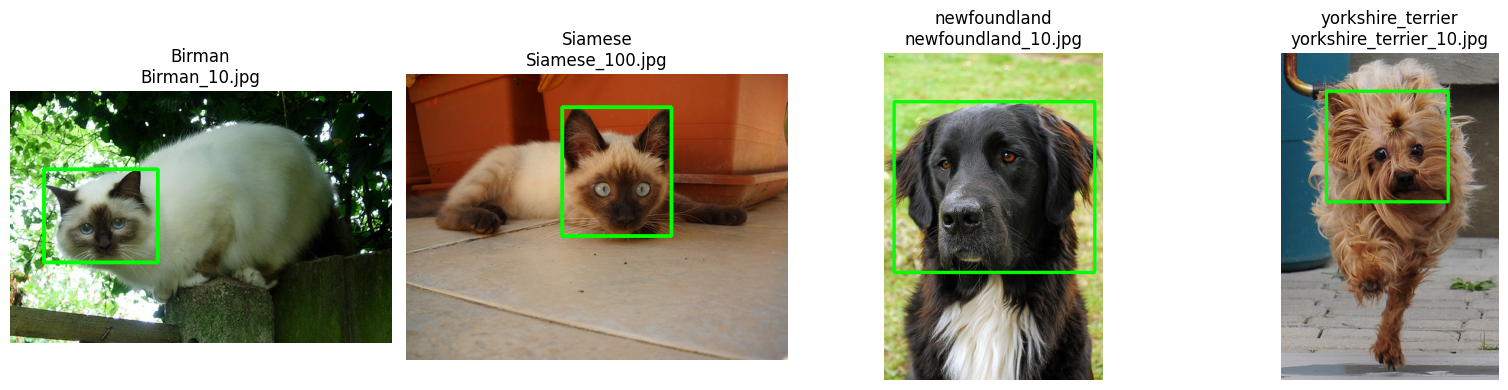

Сохранено: results/samples_grid.png


In [28]:
breeds = variant_info["breeds"]

fig, axes = plt.subplots(
    1, len(breeds),
    figsize=(4 * len(breeds), 4),
)

for ax, breed in zip(axes, breeds):
    # Выбираем фотографию этой породы с XML-разметкой
    candidates = info[
        (info["breed"] == breed) & info["has_xml"]
    ]
    sample_name = candidates.iloc[0]["filename"]
    sample_stem = Path(sample_name).stem

    # Читаем фотографию и переводим в RGB
    sample_bgr = cv2.imread(str(IMG_DIR / sample_name))
    assert sample_bgr is not None, f"Не удалось прочитать {sample_name}"
    sample_rgb = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB)

    # Рисуем все рамки из XML
    sample_boxes = read_boxes(XML_DIR / (sample_stem + ".xml"))

    for xmin, ymin, xmax, ymax in sample_boxes:
        cv2.rectangle(
            sample_rgb,
            (xmin - 1, ymin - 1),
            (xmax - 1, ymax - 1),
            (0, 255, 0),
            3,
        )

    ax.imshow(sample_rgb)
    ax.set_title(f"{breed}\n{sample_name}")
    ax.axis("off")

    print(f"{breed}: {sample_name}, рамок: {len(sample_boxes)}")

fig.tight_layout()
fig.savefig(RESULTS / "samples_grid.png", dpi=150)
plt.show()

print("Сохранено:", RESULTS / "samples_grid.png")

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [29]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

                   metric  value
                  variant     22
                  n_files    800
                 n_breeds      4
                   n_cats    400
                   n_dogs    400
                width_min    133
             width_median  500.0
                width_max    679
               height_min    150
            height_median  375.0
               height_max    798
                n_non_rgb      0
           n_jpg_not_jpeg      0
               n_with_xml    400
         xml_coverage_pct   50.0
           n_breed_Birman    200
          n_breed_Siamese    200
     n_breed_newfoundland    200
n_breed_yorkshire_terrier    200
не хватает: ничего, все 3 файла на месте


In [30]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>